# EN3160 - Assignment 03

**Name:** Ayanaja N.B.G.M

**Index Number:** 230065H

**Repository:** https://github.com/ManiiAya/EN3160-Assignment-03

In [9]:
import torch
import torch.nn.functional as F
import numpy as np
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
import torch.nn as nn
from torch.utils.data import DataLoader,  random_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


Device: cpu


In [ ]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5),
                         (0.5, 0.5, 0.5))
])

trainset = datasets.ImageFolder(
    root="./data/cifar10/train",
    transform=transform
)

testset = datasets.ImageFolder(
    root="./data/cifar10/test",
    transform=transform
)

trainloader = DataLoader(
    trainset, batch_size=50, shuffle=True, num_workers=0
)

testloader = DataLoader(
    testset, batch_size=50, shuffle=False, num_workers=0
)

print("Training images:", len(trainset))
print("Test images:", len(testset))
print("Classes:", trainset.classes)

Device: cpu
Training images: 50000
Test images: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [8]:
Din = 3 * 32 * 32
H = 100
K = 10

# First layer: 3072 -> 100
W1 = torch.randn(Din, H, device=device) * (1 / Din**0.5)
b1 = torch.zeros(H, device=device)

# Second layer: 100 -> 10
W2 = torch.randn(H, K, device=device) * (1 / H**0.5)
b2 = torch.zeros(K, device=device)

epochs = 10
lr = 0.1
lr_decay = 0.9

loss_history = []

print("W1:", W1.shape)
print("b1:", b1.shape)
print("W2:", W2.shape)
print("b2:", b2.shape)

W1: torch.Size([3072, 100])
b1: torch.Size([100])
W2: torch.Size([100, 10])
b2: torch.Size([10])


In [9]:
def forward(x, W1, b1, W2, b2):
    z1 = x @ W1 + b1
    a1 = torch.sigmoid(z1)
    z2 = a1 @ W2 + b2

    return z1, a1, z2

In [10]:
for epoch in range(epochs):

    running_loss = 0.0

    for inputs, labels in trainloader:

        inputs = inputs.to(device)
        labels = labels.to(device)

        N = inputs.shape[0]
        x = inputs.reshape(N, -1)

        # Forward propagation
        z1, a1, z2 = forward(x, W1, b1, W2, b2)

        # Cross-entropy loss
        loss = F.cross_entropy(z2, labels)

        running_loss += loss.item()
        loss_history.append(loss.item())

        # Backpropagation
        probs = torch.softmax(z2, dim=1)
        y_onehot = F.one_hot(labels, num_classes=K).float()

        dz2 = (probs - y_onehot) / N

        dW2 = a1.T @ dz2
        db2 = dz2.sum(dim=0)

        da1 = dz2 @ W2.T
        dz1 = da1 * a1 * (1 - a1)

        dW1 = x.T @ dz1
        db1 = dz1.sum(dim=0)

        # Parameter updates
        W1 -= lr * dW1
        b1 -= lr * db1
        W2 -= lr * dW2
        b2 -= lr * db2

    avg_loss = running_loss / len(trainloader)

    print(f"Epoch {epoch+1}/{epochs}, Loss: {avg_loss:.4f}")

    lr *= lr_decay

Epoch 1/10, Loss: 1.8078
Epoch 2/10, Loss: 1.6755
Epoch 3/10, Loss: 1.6162
Epoch 4/10, Loss: 1.5680
Epoch 5/10, Loss: 1.5288
Epoch 6/10, Loss: 1.4957
Epoch 7/10, Loss: 1.4655
Epoch 8/10, Loss: 1.4404
Epoch 9/10, Loss: 1.4181
Epoch 10/10, Loss: 1.3975


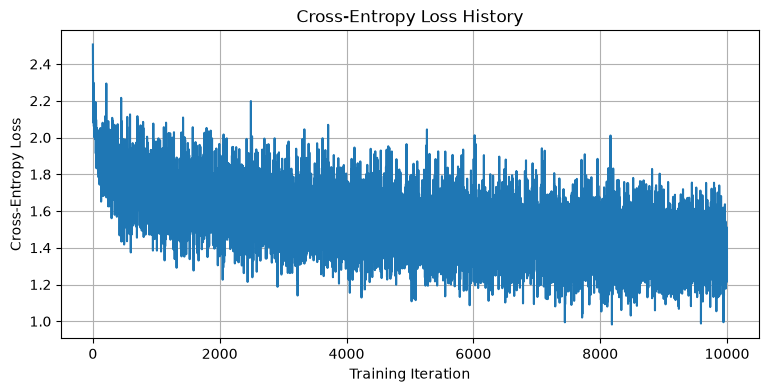

In [11]:
plt.figure(figsize=(9, 4))

plt.plot(loss_history)

plt.title("Cross-Entropy Loss History")
plt.xlabel("Training Iteration")
plt.ylabel("Cross-Entropy Loss")
plt.grid(True)
plt.show()

In [12]:
def calculate_accuracy(loader, W1, b1, W2, b2):

    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in loader:

            inputs = inputs.to(device)
            labels = labels.to(device)

            x = inputs.reshape(inputs.shape[0], -1)

            _, _, z2 = forward(x, W1, b1, W2, b2)

            predicted = z2.argmax(dim=1)

            correct += (predicted == labels).sum().item()
            total += labels.size(0)

    return 100 * correct / total


train_acc = calculate_accuracy(
    trainloader, W1, b1, W2, b2
)

test_acc = calculate_accuracy(
    testloader, W1, b1, W2, b2
)

print(f"Training Accuracy: {train_acc:.2f}%")
print(f"Test Accuracy: {test_acc:.2f}%")

Training Accuracy: 53.04%
Test Accuracy: 48.28%


In [7]:

transform = transforms.Compose([
    transforms.Pad(2),
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

full_train = datasets.MNIST("data", train=True, download=True, transform=transform)
test_set = datasets.MNIST("data", train=False, download=True, transform=transform)

train_set, val_set = random_split(
    full_train, [54000, 6000],
    generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(train_set, batch_size=128, shuffle=True)
val_loader = DataLoader(val_set, batch_size=128)
test_loader = DataLoader(test_set, batch_size=128)

print("Training:", len(train_set))
print("Validation:", len(val_set))
print("Testing:", len(test_set))


100%|██████████| 9.91M/9.91M [00:03<00:00, 3.16MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 98.4kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 923kB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 15.9MB/s]

Training: 54000
Validation: 6000
Testing: 10000


In [10]:

class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 6, 5), nn.ReLU(),
            nn.AvgPool2d(2),
            nn.Conv2d(6, 16, 5), nn.ReLU(),
            nn.AvgPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(16 * 5 * 5, 120), nn.ReLU(),
            nn.Linear(120, 84), nn.ReLU(),
            nn.Linear(84, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


In [11]:

class CustomCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1),
            nn.BatchNorm2d(32), nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128), nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


In [13]:

def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)

    total_loss, correct, total = 0, 0, 0

    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)

            if training:
                optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            if training:
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)

    return total_loss / total, correct / total


In [14]:

def train_model(model, epochs=10):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    history = {"train_loss": [], "train_acc": [],
               "val_loss": [], "val_acc": []}

    for epoch in range(epochs):
        tl, ta = run_epoch(model, train_loader, criterion, optimizer)
        vl, va = run_epoch(model, val_loader, criterion)

        for key, value in zip(history, [tl, ta, vl, va]):
            history[key].append(value)

        print(f"Epoch {epoch+1:2d}/{epochs} | "
              f"Train Acc: {ta:.4f} | Val Acc: {va:.4f}")

    return model, history


lenet, lenet_hist = train_model(LeNet5())
custom, custom_hist = train_model(CustomCNN())


Epoch  1/10 | Train Acc: 0.8819 | Val Acc: 0.9523
Epoch  2/10 | Train Acc: 0.9683 | Val Acc: 0.9720
Epoch  3/10 | Train Acc: 0.9770 | Val Acc: 0.9772
Epoch  4/10 | Train Acc: 0.9819 | Val Acc: 0.9797
Epoch  5/10 | Train Acc: 0.9852 | Val Acc: 0.9828
Epoch  6/10 | Train Acc: 0.9869 | Val Acc: 0.9837
Epoch  7/10 | Train Acc: 0.9881 | Val Acc: 0.9858
Epoch  8/10 | Train Acc: 0.9896 | Val Acc: 0.9868
Epoch  9/10 | Train Acc: 0.9915 | Val Acc: 0.9860
Epoch 10/10 | Train Acc: 0.9919 | Val Acc: 0.9863
Epoch  1/10 | Train Acc: 0.9282 | Val Acc: 0.9858
Epoch  2/10 | Train Acc: 0.9757 | Val Acc: 0.9862
Epoch  3/10 | Train Acc: 0.9818 | Val Acc: 0.9888
Epoch  4/10 | Train Acc: 0.9845 | Val Acc: 0.9852
Epoch  5/10 | Train Acc: 0.9868 | Val Acc: 0.9858
Epoch  6/10 | Train Acc: 0.9885 | Val Acc: 0.9913
Epoch  7/10 | Train Acc: 0.9895 | Val Acc: 0.9905
Epoch  8/10 | Train Acc: 0.9890 | Val Acc: 0.9897
Epoch  9/10 | Train Acc: 0.9911 | Val Acc: 0.9897
Epoch 10/10 | Train Acc: 0.9921 | Val Acc: 0.9928


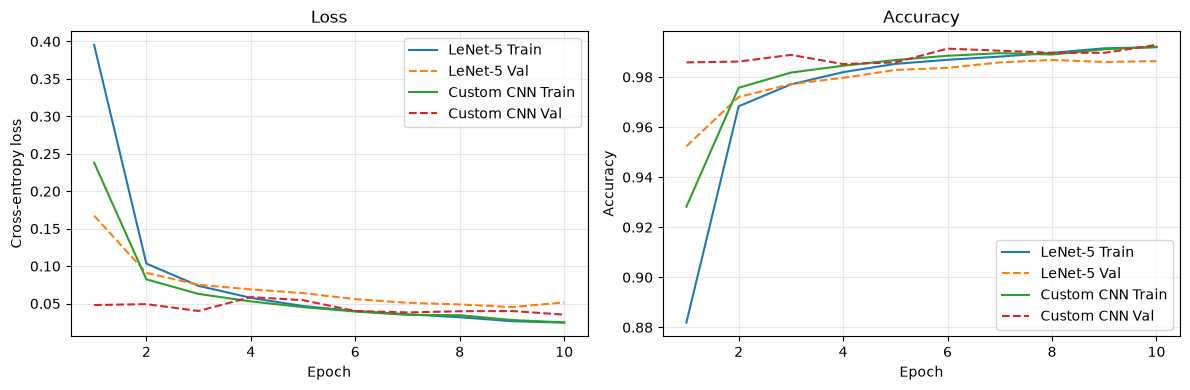

In [15]:

epochs = range(1, 11)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for name, hist in [("LeNet-5", lenet_hist), ("Custom CNN", custom_hist)]:
    axes[0].plot(epochs, hist["train_loss"], label=f"{name} Train")
    axes[0].plot(epochs, hist["val_loss"], "--", label=f"{name} Val")
    axes[1].plot(epochs, hist["train_acc"], label=f"{name} Train")
    axes[1].plot(epochs, hist["val_acc"], "--", label=f"{name} Val")

axes[0].set(title="Loss", xlabel="Epoch", ylabel="Cross-entropy loss")
axes[1].set(title="Accuracy", xlabel="Epoch", ylabel="Accuracy")

for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


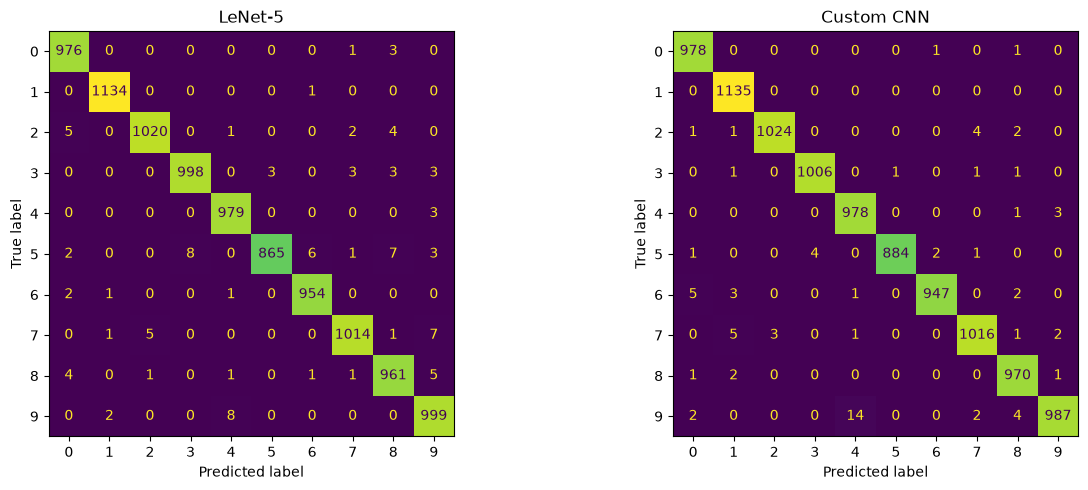

In [16]:

def evaluate_predictions(model, loader):
    model.eval()
    y_true, y_pred = [], []

    with torch.no_grad():
        for images, labels in loader:
            outputs = model(images.to(device))
            y_true.extend(labels.numpy())
            y_pred.extend(outputs.argmax(1).cpu().numpy())

    return np.array(y_true), np.array(y_pred)


fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (name, model) in zip(
    axes, [("LeNet-5", lenet), ("Custom CNN", custom)]
):
    y_true, y_pred = evaluate_predictions(model, test_loader)
    cm = confusion_matrix(y_true, y_pred, labels=range(10))

    ConfusionMatrixDisplay(cm, display_labels=range(10)).plot(
        ax=ax, colorbar=False, values_format="d"
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()


In [17]:

criterion = nn.CrossEntropyLoss()

for name, model in [("LeNet-5", lenet), ("Custom CNN", custom)]:
    loss, acc = run_epoch(model, test_loader, criterion)
    params = sum(p.numel() for p in model.parameters())

    print(f"{name}: Test Loss={loss:.4f}, "
          f"Test Accuracy={acc:.2%}, Parameters={params:,}")


LeNet-5: Test Loss=0.0330, Test Accuracy=99.00%, Parameters=61,706
Custom CNN: Test Loss=0.0263, Test Accuracy=99.25%, Parameters=356,682


In [18]:

import os
import copy
import time
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
from torch.optim import SGD
from torch.optim.lr_scheduler import StepLR

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


Device: cpu


In [19]:

mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

data_transforms = {
    "train": transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(mean, std)
    ]),
    "val": transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(mean, std)
    ])
}


In [20]:

data_dir = "data/hymenoptera_data"

image_datasets = {
    x: datasets.ImageFolder(
        os.path.join(data_dir, x), data_transforms[x]
    )
    for x in ["train", "val"]
}

dataloaders = {
    x: DataLoader(
        image_datasets[x], batch_size=4,
        shuffle=(x == "train"), num_workers=0
    )
    for x in ["train", "val"]
}

dataset_sizes = {x: len(image_datasets[x]) for x in ["train", "val"]}
class_names = image_datasets["train"].classes

print("Classes:", class_names)
print("Dataset sizes:", dataset_sizes)


Classes: ['ants', 'bees']
Dataset sizes: {'train': 244, 'val': 153}


In [21]:

def train_model(model, optimizer, scheduler, epochs=15,
                feature_extract=False):
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "train_acc": [],
               "val_loss": [], "val_acc": []}

    best_weights = copy.deepcopy(model.state_dict())
    best_acc = 0.0
    start = time.time()

    for epoch in range(epochs):
        for phase in ["train", "val"]:
            model.train(phase == "train")

            # Keep the pretrained backbone fixed, including BN statistics.
            if feature_extract:
                model.eval()

            loss_sum, correct = 0.0, 0

            for images, labels in dataloaders[phase]:
                images = images.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == "train"):
                    outputs = model(images)
                    loss = criterion(outputs, labels)

                    if phase == "train":
                        loss.backward()
                        optimizer.step()

                loss_sum += loss.item() * images.size(0)
                correct += (outputs.argmax(1) == labels).sum().item()

            epoch_loss = loss_sum / dataset_sizes[phase]
            epoch_acc = correct / dataset_sizes[phase]

            history[f"{phase}_loss"].append(epoch_loss)
            history[f"{phase}_acc"].append(epoch_acc)

            if phase == "val" and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_weights = copy.deepcopy(model.state_dict())

        scheduler.step()

        print(f"Epoch {epoch+1:02d}/{epochs} | "
              f"Train: {history['train_acc'][-1]:.3f} | "
              f"Val: {history['val_acc'][-1]:.3f}")

    elapsed = time.time() - start
    model.load_state_dict(best_weights)

    return model, history, best_acc, elapsed


In [22]:

weights = models.ResNet18_Weights.IMAGENET1K_V1

model_ft = models.resnet18(weights=weights)
model_ft.fc = nn.Linear(model_ft.fc.in_features, 2)
model_ft = model_ft.to(device)

optimizer_ft = SGD(model_ft.parameters(), lr=0.001, momentum=0.9)
scheduler_ft = StepLR(optimizer_ft, step_size=7, gamma=0.1)

model_ft, hist_ft, acc_ft, time_ft = train_model(
    model_ft, optimizer_ft, scheduler_ft, epochs=15
)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\Manitha Ayanaja/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:05<00:00, 8.37MB/s]


Epoch 01/15 | Train: 0.668 | Val: 0.869
Epoch 02/15 | Train: 0.820 | Val: 0.922
Epoch 03/15 | Train: 0.750 | Val: 0.869
Epoch 04/15 | Train: 0.828 | Val: 0.869
Epoch 05/15 | Train: 0.807 | Val: 0.791
Epoch 06/15 | Train: 0.779 | Val: 0.712
Epoch 07/15 | Train: 0.713 | Val: 0.856
Epoch 08/15 | Train: 0.848 | Val: 0.908
Epoch 09/15 | Train: 0.795 | Val: 0.922
Epoch 10/15 | Train: 0.852 | Val: 0.935
Epoch 11/15 | Train: 0.885 | Val: 0.915
Epoch 12/15 | Train: 0.836 | Val: 0.928
Epoch 13/15 | Train: 0.848 | Val: 0.922
Epoch 14/15 | Train: 0.869 | Val: 0.915
Epoch 15/15 | Train: 0.918 | Val: 0.915
